# Predicting Income Level Using Machine Learning Models
This notebook contains all data preprocessing steps, exploratory data analysis, model training, and evaluation used in the accompanying paper.  

# 1. Data Loading and Initial Exploration
  
The Adult Income dataset from the U.S. Census Bureau is used in this study.  
It contains demographic and employment-related attributes and a binary income variable  
indicating whether an individual's annual income exceeds $50,000.  

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("data/adult.csv")
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
df.shape

(48842, 15)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [5]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [6]:
df.isnull().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

In [7]:
(df == '?').sum()

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

### 2. Data Cleaning and Preprocessing
  
Although the dataset does not contain explicit missing values,  
some categorical variables include "?" symbols representing unknown entries.  
These values are treated as missing and removed to ensure data quality.  

In [8]:
df = df.replace('?', np.nan)

In [9]:
df.isnull().sum()

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

In [10]:
df = df.dropna()

In [11]:
df.shape

(45222, 15)

In [12]:
df['income'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)

In [13]:
df['income'].value_counts(normalize=True)

income
0    0.752156
1    0.247844
Name: proportion, dtype: float64

### 3. Exploratory Data Analysis
  
Exploratory analysis is conducted to understand the distribution of key variables  
and identify potential relationships between predictors and income level.  

#### Age Distribution
  
This figure shows the distribution of individuals' ages in the dataset,  
indicating a concentration in the working-age population.  

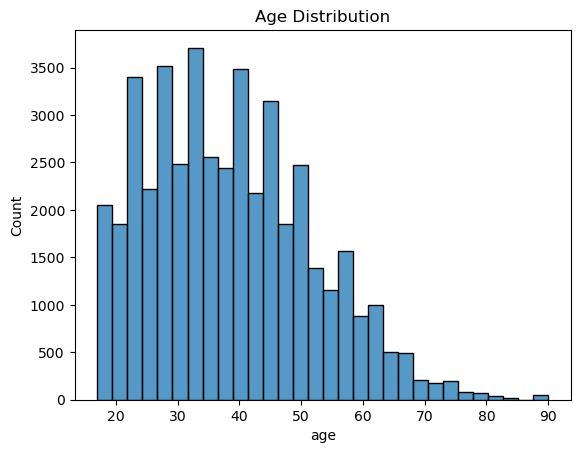

In [14]:
plt.figure()
sns.histplot(df['age'], bins=30)
plt.title("Age Distribution")
plt.show()

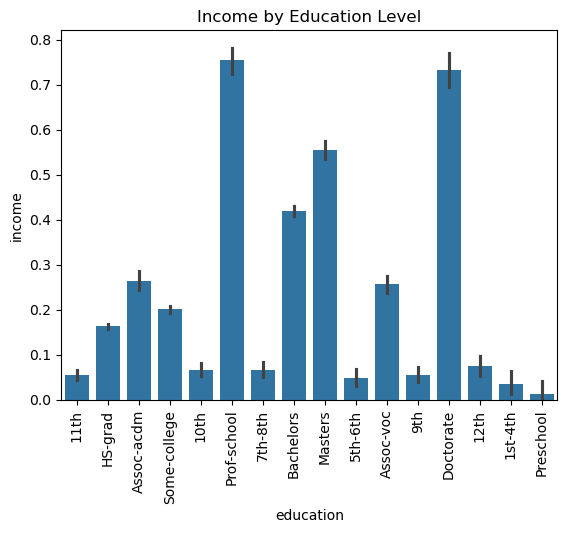

In [15]:
plt.figure()
sns.barplot(x='education', y='income', data=df)
plt.xticks(rotation=90)
plt.title("Income by Education Level")
plt.show()

### Correlation Analysis
  
Correlation analysis is performed on numerical variables to examine linear relationships  
between continuous features and income-related factors.  

In [16]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])


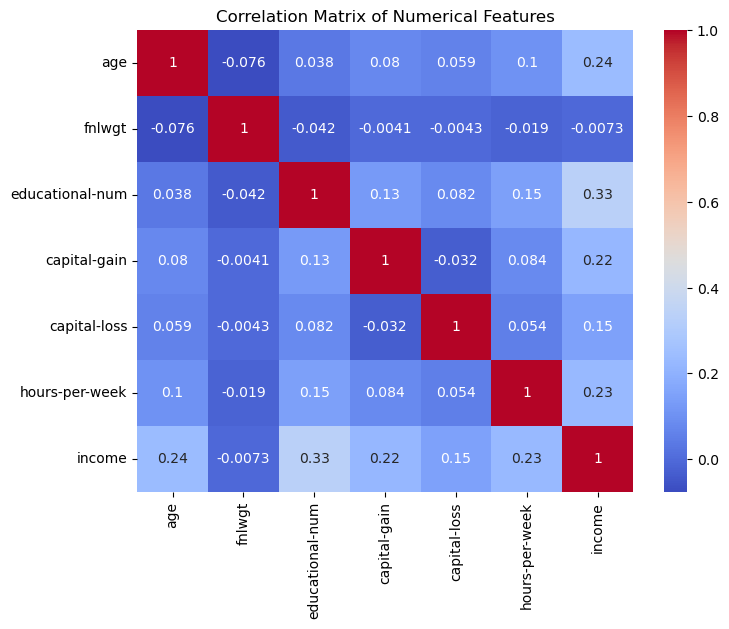

In [17]:
plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix of Numerical Features")
plt.show()


Подготовка данных для ML  

In [19]:
X = df.drop('income', axis=1)
y = df['income']

In [20]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns


In [22]:
X = pd.get_dummies(X, drop_first=True)


Train / Test Split  

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

Logistic Regression  

In [51]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:,1]


Decision Tree  

In [53]:
dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:,1]


random forest  

In [55]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:,1]


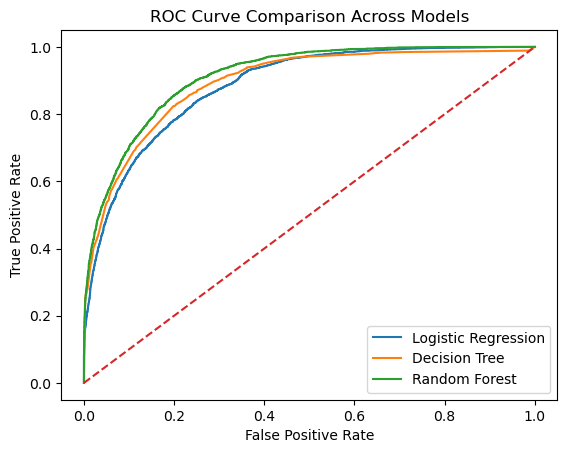

In [89]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,       
    "Random Forest": rf        
}

plt.figure()
for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison Across Models")
plt.legend()
plt.show()


## 6. Model Evaluation
  
Model performance is assessed using multiple metrics, including accuracy,  
precision, recall, F1-score, and ROC-AUC, to provide a comprehensive comparison.  

In [57]:
def evaluate_model(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }


In [59]:
results = pd.DataFrame({
    "Logistic Regression": evaluate_model(y_test, y_pred_lr, y_prob_lr),
    "Decision Tree": evaluate_model(y_test, y_pred_dt, y_prob_dt),
    "Random Forest": evaluate_model(y_test, y_pred_rf, y_prob_rf)
}).T

results


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.837989,0.718962,0.568412,0.634884,0.883877
Decision Tree,0.848972,0.757552,0.574360,0.653358,0.892803
Random Forest,0.853099,0.782734,0.563653,0.655369,0.912584


### Confusion matrix (Random Forest)

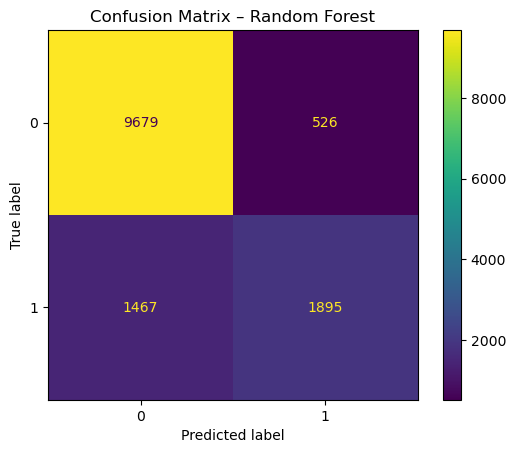

In [79]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix – Random Forest")
plt.show()
